# Neurophysiology sanity check

Pre-design check of the diagnostics stage. No training. Questions:

- Do the MRCP and mu/beta ERD exist in this data, and are they lateralized?
- What is their timing relative to kinematic onset?
- Can onset-aligned and LED-aligned averages be told apart?
- Does the lateralization agree with right-hand movement?

Analysis windows are fixed in `configs/diagnostics/neurophysiology.yaml`. Library code: `eegtraj.diagnostics.neurophysiology`.

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
import yaml

if Path.cwd().name == "notebook":
    os.chdir("..")

from eegtraj.diagnostics.neurophysiology import (analyze_subject, filter_delay_ms, laterality_stats, laterality_table,
                                                 paired_summary, percent_change, rt_split_table, window_mean)
from eegtraj.preprocessing.bad_channels import MONTAGE
from eegtraj.preprocessing.filters import butter_sos
from eegtraj.utils.run import setup_run

cfg = yaml.safe_load(Path("configs/diagnostics/neurophysiology.yaml").read_text(encoding="utf-8"))
run_dir = setup_run(cfg["output_dir"], cfg)
fig_dir = run_dir / "figures"
fig_dir.mkdir()
print(run_dir)

# First three categorical slots of the reference chart palette; they stay assigned to the same role.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight", "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
                     "lines.linewidth": 2, "legend.frameon": False, "text.color": INK, "axes.labelcolor": MUTED,
                     "xtick.color": MUTED, "ytick.color": MUTED})


def save(fig, name):
    fig.savefig(fig_dir / f"{name}.png")
    plt.show()

2026-11-06 13:28:06 INFO    eegtraj.utils.run: Run directory: output\diagnostics\pre-design\neurophysiology\20261106-132757


output\diagnostics\pre-design\neurophysiology\20261106-132757


## Channel positions

CAR and C3/C4 labels decide every laterality statement, so the side of each channel is checked against the montage.

In [2]:
montage = mne.channels.make_standard_montage(MONTAGE).get_positions()["ch_pos"]
for ch in cfg["laterality"]["contralateral"]:
    assert montage[ch][0] < 0, ch
for ch in cfg["laterality"]["ipsilateral"]:
    assert montage[ch][0] > 0, ch
print("left:", cfg["laterality"]["contralateral"], "right:", cfg["laterality"]["ipsilateral"])

left: ['C3', 'FC5', 'FC1', 'CP5', 'CP1'] right: ['C4', 'FC6', 'FC2', 'CP6', 'CP2']


## Per-subject analysis

Lifts inside the filter start-up transient are left out of these averages. Decoder runs are not affected.

In [3]:
results = [analyze_subject(cfg, s) for s in cfg["subjects"]]
names = results[0]["names"]
assert all(r["names"] == names for r in results)
overview = pd.DataFrame([{k: r[k] for k in ("subject", "n_lifts", "n_kept", "rt_median_s", "rt_iqr_s", "rt_fast_median_s",
                                            "rt_slow_median_s")} for r in results]).round(3)
overview

,subject,n_lifts,n_kept,rt_median_s,rt_iqr_s,rt_fast_median_s,rt_slow_median_s
0,P1,294,279,0.306,0.100,0.264,0.396
1,P2,294,280,0.604,0.269,0.488,1.016
2,P4,294,280,0.300,0.064,0.258,0.339
3,P5,294,280,0.479,0.190,0.348,0.612
4,P7,294,281,0.700,0.302,0.515,0.994
5,P8,294,280,0.354,0.089,0.298,0.426
6,P9,294,281,0.354,0.130,0.280,0.475
7,P10,294,279,0.378,0.130,0.315,0.501
8,P11,294,280,0.374,0.132,0.310,0.510
9,P12,294,280,0.435,0.212,0.340,0.610


## Causal filter delay

MRCP timing below includes this delay. Peaks and starts in the causal signal appear this much later than in the brain.

In [4]:
base = yaml.safe_load(Path(cfg["cache_config"]).read_text(encoding="utf-8"))
fs_raw = 500.0
sos_band = butter_sos(fs_raw, base["eeg"]["filter_order"], *cfg["erp"]["band_hz"])
sos_aa = butter_sos(fs_raw, base["eeg"]["antialias"]["order"],
                    high_hz=base["eeg"]["antialias"]["frac_of_nyquist"] * base["fs_out_hz"] / 2)
delays = filter_delay_ms([sos_band, sos_aa], fs_raw, cfg["filter_delay_hz"])
pd.Series(delays, name="group delay (ms)").round(1).to_frame()

,group delay (ms)
0.5,224.0
1.0,172.4
2.0,134.6


## MRCP at Cz, C3, and C4

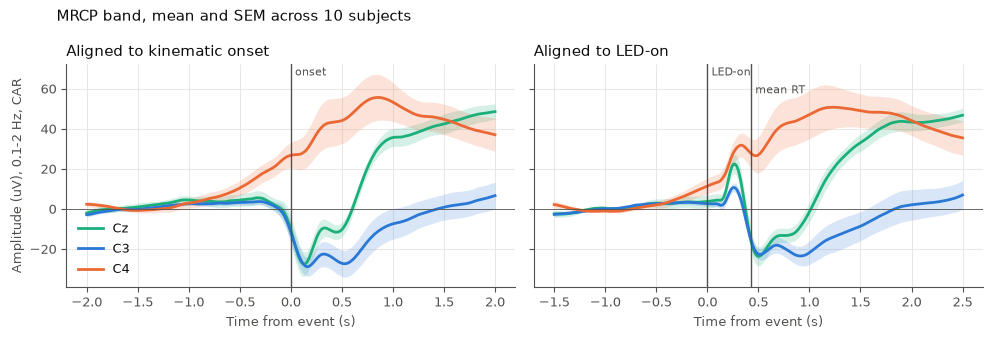

In [5]:
def group_trace(key, event, ch):
    c = names.index(ch)
    x = np.stack([r[key][event][c] if event else r[key][c] for r in results])
    return np.nanmean(x, axis=0), np.nanstd(x, axis=0, ddof=1) / np.sqrt(len(x)) if len(x) > 1 else 0 * x[0]


def draw(ax, t, mean, sem, color, label):
    ax.fill_between(t, mean - sem, mean + sem, color=color, alpha=0.18, linewidth=0)
    ax.plot(t, mean, color=color, label=label)


def mark(ax, label, x=0.0, y=1.0):
    ax.axvline(x, color=MUTED, linewidth=1)
    ax.annotate(label, (x, y), xycoords=("data", "axes fraction"), xytext=(3, -2), textcoords="offset points",
                va="top", color=MUTED, fontsize=8)


colors = dict(zip(cfg["plots"]["mrcp_channels"], (AQUA, BLUE, ORANGE)))
median_rt = float(np.mean([r["rt_median_s"] for r in results]))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, event, title in zip(axes, ("onset", "led"), ("Aligned to kinematic onset", "Aligned to LED-on")):
    for ch, color in colors.items():
        draw(ax, results[0]["erp_times"][event], *group_trace("erp", event, ch), color, ch)
    mark(ax, "onset" if event == "onset" else "LED-on")
    if event == "led":
        mark(ax, "mean RT", median_rt, 0.92)
    ax.axhline(0, color=MUTED, linewidth=0.6)
    ax.set_title(title, loc="left")
    ax.set_xlabel("Time from event (s)")
axes[0].set_ylabel("Amplitude (uV), 0.1-2 Hz, CAR")
axes[0].legend(loc="lower left")
fig.suptitle(f"MRCP band, mean and SEM across {len(results)} subjects", x=0.06, ha="left")
fig.tight_layout()
save(fig, "mrcp_grand_average")

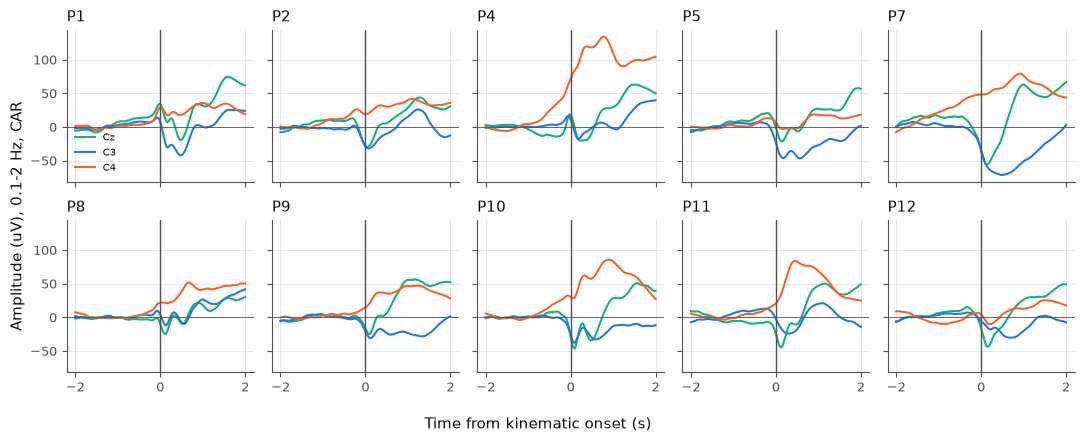

In [6]:
ncol = 5
nrow = int(np.ceil(len(results) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(11, 2.2 * nrow), sharex=True, sharey=True, squeeze=False)
for ax, r in zip(axes.flat, results):
    for ch, color in colors.items():
        ax.plot(r["erp_times"]["onset"], r["erp"]["onset"][names.index(ch)], color=color, label=ch, linewidth=1.5)
    ax.axvline(0, color=MUTED, linewidth=1)
    ax.axhline(0, color=MUTED, linewidth=0.6)
    ax.set_title(r["subject"], loc="left")
for ax in axes.flat[len(results):]:
    ax.set_visible(False)
axes[0, 0].legend(loc="lower left", fontsize=7)
fig.supxlabel("Time from kinematic onset (s)")
fig.supylabel("Amplitude (uV), 0.1-2 Hz, CAR")
fig.tight_layout()
save(fig, "mrcp_per_subject")

## Occipital response to the LED

The 0.1-2 Hz band cannot resolve a response at 100-200 ms, so the broadband average is shown as well.

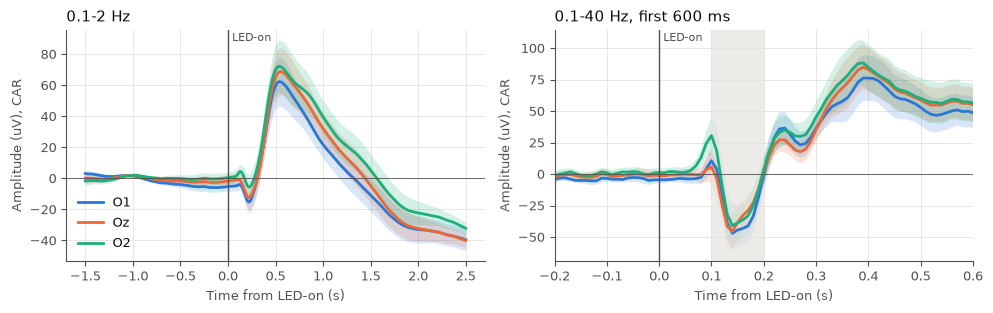

In [7]:
occ_colors = dict(zip(cfg["plots"]["occipital_channels"], (BLUE, ORANGE, AQUA)))
t = results[0]["erp_times"]["led"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ch, color in occ_colors.items():
    draw(axes[0], t, *group_trace("erp", "led", ch), color, ch)
    c = names.index(ch)
    x = np.stack([r["vep"][c] for r in results])
    draw(axes[1], t, x.mean(0), x.std(0, ddof=1) / np.sqrt(len(x)) if len(x) > 1 else 0 * t, color, ch)
axes[0].set_title("0.1-2 Hz", loc="left")
axes[1].set_title("0.1-40 Hz, first 600 ms", loc="left")
axes[1].set_xlim(-0.2, 0.6)
for ax in axes:
    mark(ax, "LED-on")
    ax.axhline(0, color=MUTED, linewidth=0.6)
    ax.set_xlabel("Time from LED-on (s)")
    ax.set_ylabel("Amplitude (uV), CAR")
axes[1].axvspan(0.1, 0.2, color=GRID, alpha=0.7, linewidth=0)
axes[0].legend(loc="lower left")
fig.tight_layout()
save(fig, "occipital_led")

## Prefrontal channels

Fp1 and Fp2 show eye activity, which matters because they carried most of the gain in r from a longer history.

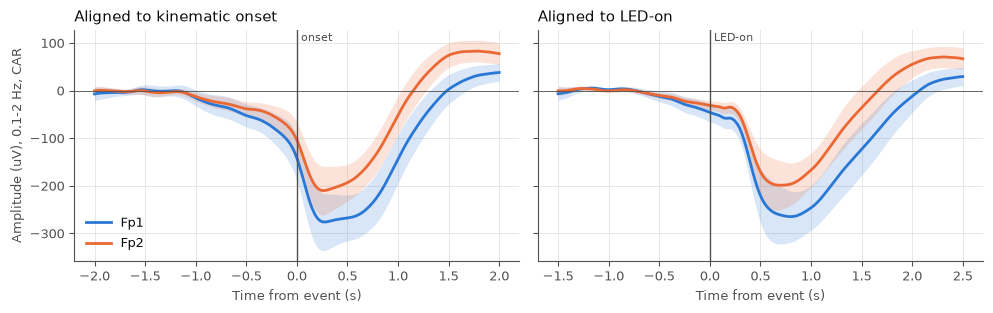

In [8]:
pf_colors = dict(zip(cfg["plots"]["prefrontal_channels"], (BLUE, ORANGE)))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for ax, event, title in zip(axes, ("onset", "led"), ("Aligned to kinematic onset", "Aligned to LED-on")):
    for ch, color in pf_colors.items():
        draw(ax, results[0]["erp_times"][event], *group_trace("erp", event, ch), color, ch)
    mark(ax, "onset" if event == "onset" else "LED-on")
    ax.axhline(0, color=MUTED, linewidth=0.6)
    ax.set_title(title, loc="left")
    ax.set_xlabel("Time from event (s)")
axes[0].set_ylabel("Amplitude (uV), 0.1-2 Hz, CAR")
axes[0].legend(loc="lower left")
fig.tight_layout()
save(fig, "prefrontal")

## Mu and beta power at C3 and C4

Percent change from the mean power 1.5 to 0.5 s before LED-on, averaged across subjects. Blue is a decrease (ERD), red an increase (ERS). The neutral midpoint is zero change.

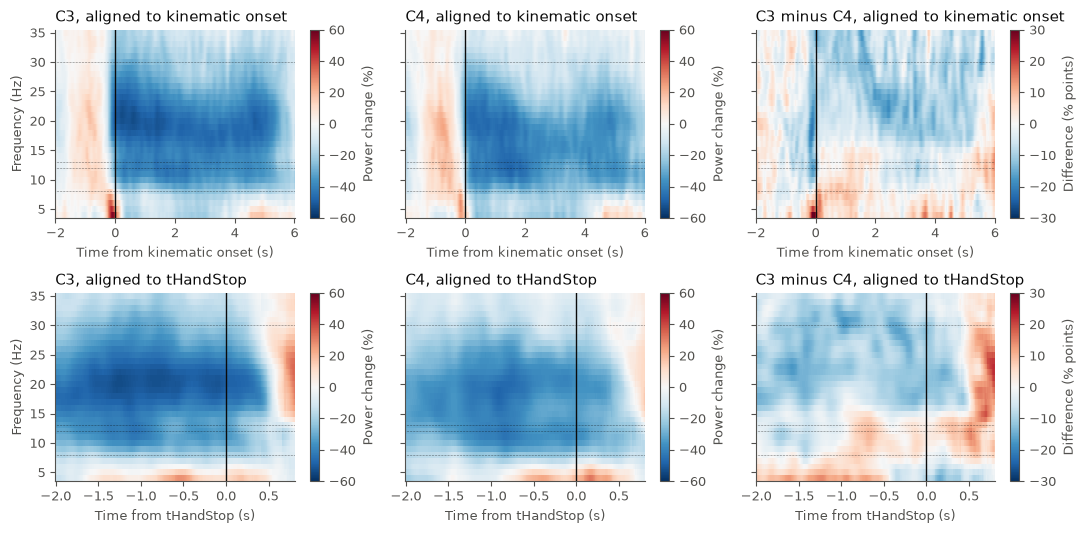

In [9]:
freqs = results[0]["freqs_hz"]
a, b = cfg["plots"]["tf_channels"]
ia, ib = names.index(a), names.index(b)


def group_change(event):
    return np.nanmean(np.stack([percent_change(r["tf_power"][event], r["tf_baseline"]) for r in results]), axis=0)


fig, axes = plt.subplots(2, 3, figsize=(11, 5.4), sharey=True, sharex="row")
for row, (event, label) in enumerate((("onset", "kinematic onset"), ("tHandStop", "tHandStop"))):
    change = group_change(event)
    t = results[0]["tf_times"][event]
    for col, (map_, title, lim) in enumerate(((change[ia], a, 60), (change[ib], b, 60),
                                              (change[ia] - change[ib], f"{a} minus {b}", 30))):
        ax = axes[row, col]
        im = ax.pcolormesh(t, freqs, map_, cmap="RdBu_r", vmin=-lim, vmax=lim, shading="auto", rasterized=True)
        ax.axvline(0, color=INK, linewidth=1)
        for edge in (8, 12, 13, 30):
            ax.axhline(edge, color=INK, linewidth=0.4, linestyle=":")
        ax.grid(False)
        ax.set_title(f"{title}, aligned to {label}", loc="left")
        ax.set_xlabel(f"Time from {label} (s)")
        fig.colorbar(im, ax=ax, label="Power change (%)" if col < 2 else "Difference (% points)")
    axes[row, 0].set_ylabel("Frequency (Hz)")
fig.tight_layout()
save(fig, "tf_c3_c4")

## Scalp maps

Grand averages in the windows fixed in the config.

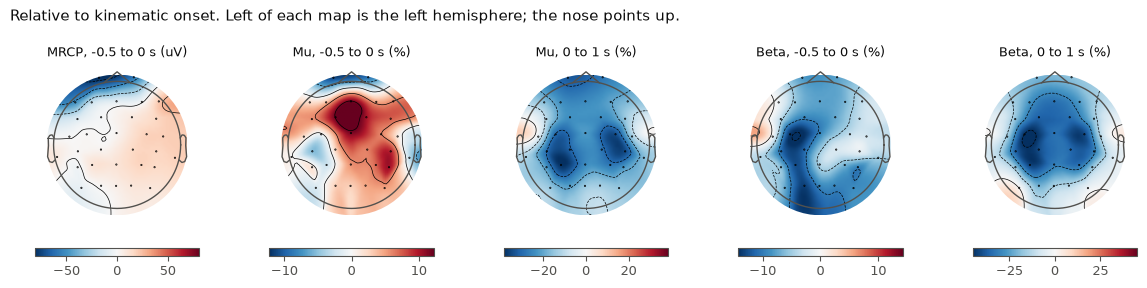

In [10]:
info = mne.create_info(names, results[0]["fs_hz"], ch_types="eeg", verbose="error")
info.set_montage(MONTAGE, verbose="error")
win = cfg["windows_s"]


def group_band(band, event, window):
    from eegtraj.diagnostics.neurophysiology import band_window_change
    return np.mean([band_window_change(r["tf_power"][event], r["tf_baseline"], freqs, r["tf_times"][event],
                                       cfg["bands_hz"][band], window) for r in results], axis=0)


maps = [("MRCP, -0.5 to 0 s (uV)", np.mean([window_mean(r["erp"]["onset"], r["erp_times"]["onset"], win["mrcp"]) for r in results], axis=0)),
        ("Mu, -0.5 to 0 s (%)", group_band("mu", "onset", win["erd_pre"])),
        ("Mu, 0 to 1 s (%)", group_band("mu", "onset", win["erd_move"])),
        ("Beta, -0.5 to 0 s (%)", group_band("beta", "onset", win["erd_pre"])),
        ("Beta, 0 to 1 s (%)", group_band("beta", "onset", win["erd_move"]))]
fig, axes = plt.subplots(1, 5, figsize=(12, 2.9))
for ax, (title, values) in zip(axes, maps):
    lim = float(np.nanmax(np.abs(values)))
    im, _ = mne.viz.plot_topomap(values, info, axes=ax, show=False, cmap="RdBu_r", vlim=(-lim, lim), contours=4)
    ax.set_title(title, fontsize=9)
    fig.colorbar(im, ax=ax, shrink=0.7, orientation="horizontal")
fig.suptitle("Relative to kinematic onset. Left of each map is the left hemisphere; the nose points up.", x=0.02, ha="left")
fig.tight_layout()
save(fig, "topomaps")

## Lateralization across subjects

Empirical check of the hand used. Differences are left minus right. A negative value is the direction expected from right-hand movement: larger negativity for the MRCP, stronger power decrease for mu and beta.

In [11]:
table = laterality_table(results, cfg)
stats = laterality_stats(table, cfg)
table.to_csv(run_dir / "laterality_per_subject.csv", index=False)
stats.to_csv(run_dir / "laterality_stats.csv", index=False)
stats.round(3)

,measure,contrast,left_mean,right_mean,diff_mean,diff_sd,n_negative,n_subjects,wilcoxon_p
0,beta_move,C3-C4,-45.215,-41.447,-3.769,9.048,7,10,0.232
1,beta_move,contra-ipsi,-35.602,-32.133,-3.469,3.108,9,10,0.014
2,beta_pre,C3-C4,-14.234,-3.461,-10.772,10.165,9,10,0.006
3,beta_pre,contra-ipsi,-10.028,-3.573,-6.456,4.608,10,10,0.002
4,beta_rebound,C3-C4,-33.156,-28.928,-4.228,11.229,5,10,0.375
5,beta_rebound,contra-ipsi,-22.906,-20.090,-2.815,4.936,7,10,0.193
6,mrcp,C3-C4,1.028,18.555,-17.527,18.104,9,10,0.006
7,mrcp,contra-ipsi,-1.203,15.175,-16.378,18.724,8,10,0.010
8,mu_move,C3-C4,-30.435,-34.753,4.318,18.991,6,10,1.000
9,mu_move,contra-ipsi,-25.288,-27.494,2.206,7.384,3,10,0.432


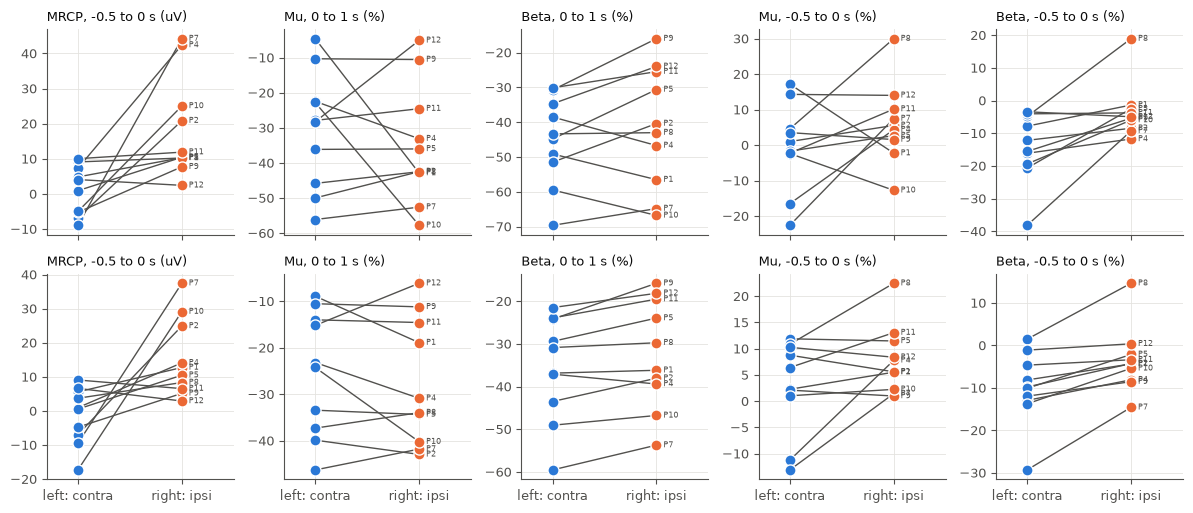

In [12]:
panels = [("mrcp", "MRCP, -0.5 to 0 s (uV)"), ("mu_move", "Mu, 0 to 1 s (%)"), ("beta_move", "Beta, 0 to 1 s (%)"),
          ("mu_pre", "Mu, -0.5 to 0 s (%)"), ("beta_pre", "Beta, -0.5 to 0 s (%)")]
fig, axes = plt.subplots(2, 5, figsize=(12, 5.2), sharex=True)
for row, (left, right) in enumerate(((a, b), ("contra", "ipsi"))):
    for ax, (m, title) in zip(axes[row], panels):
        lv, rv = table[f"{m}_{left}"], table[f"{m}_{right}"]
        for x, y, s in zip(lv, rv, table.subject):
            ax.plot([0, 1], [x, y], color=MUTED, linewidth=1, zorder=1)
            ax.annotate(s, (1, y), xytext=(5, 0), textcoords="offset points", va="center", fontsize=6, color=MUTED)
        ax.scatter([0] * len(lv), lv, s=64, color=BLUE, edgecolor="white", zorder=2)
        ax.scatter([1] * len(rv), rv, s=64, color=ORANGE, edgecolor="white", zorder=2)
        ax.set_xticks([0, 1], ["left: " + left, "right: " + right])
        ax.set_xlim(-0.3, 1.5)
        ax.set_title(title, loc="left", fontsize=9)
fig.tight_layout()
save(fig, "laterality")

## Is the MRCP asymmetry motor or ocular

Exploratory, added after the first run. A motor asymmetry should be local to sensorimotor channels. A horizontal eye-movement field is largest at F7/F8 and falls off across the scalp. The data have no EOG channel, so F7-F8 is the proxy. The original-reference row checks that CAR does not create the gradient.

In [13]:
import scipy.stats

from eegtraj.diagnostics.neurophysiology import asymmetry_table

asym = cfg["asymmetry"]
asym_table = asymmetry_table(results, asym)
asym_table.to_csv(run_dir / "asymmetry_per_subject.csv", index=False)
pair_order = [f"{p}-{q}" for p, q in asym["pairs"]]
asym_summary = asym_table.groupby(["pair", "window"]).diff_uv.agg(mean="mean", n_negative=lambda v: int((v < 0).sum())).unstack("window").reindex(pair_order)
asym_summary.round(1)

mean                   n_negative                  
window     move pre_led pre_onset       move pre_led pre_onset
pair                                                          
Fp1-Fp2   -61.3    -8.4     -24.4          9       7         7
F7-F8    -145.7   -28.4     -67.2          8       8         8
F3-F4     -47.8    -3.3     -14.9         10       6         9
FC5-FC6   -70.4    -7.1     -25.9          9       6         8
FC1-FC2   -30.2    -1.4      -9.4         10       4         7
T7-T8     -43.3    -5.9     -20.0          8       7         7
C3-C4     -60.1    -4.0     -17.5         10       5         9
CP5-CP6   -37.9    -5.0     -15.8          9       8         9
CP1-CP2   -35.9    -4.6     -13.3         10       6         9
TP9-TP10  -16.9    -4.7     -12.0          7       5         7
P7-P8     -30.4    -6.2     -18.4          9       8         9
P3-P4     -20.7    -2.0      -7.4          9       8         9
PO9-PO10  -17.8    -8.5     -15.2          8       8         9
O1-O2     -10.9    -5.2      -8.1          7       7         8

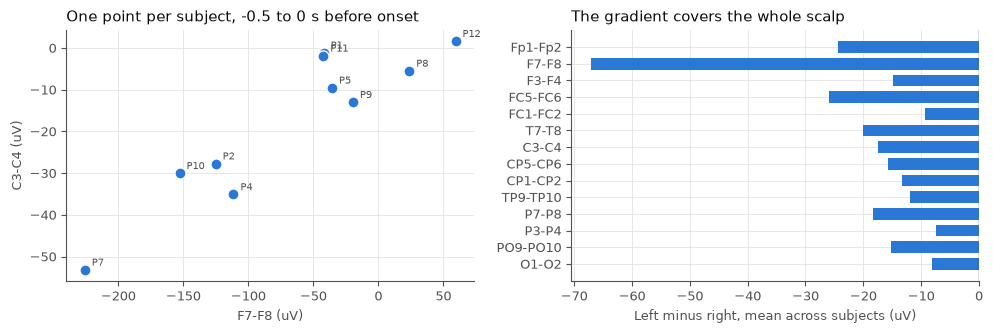

{'spearman_across_subjects': {'move': 0.8909090909090909,
  'pre_led': 0.7696969696969697,
  'pre_onset': 0.7696969696969697},
 'lift_r_median': {'pre_led': 0.44339179038371895,
  'pre_onset': 0.37827225658629726,
  'move': 0.3573786683716277},
 'orig_reference_mean_uv': {'C3-C4': -21.448443031311037,
  'F7-F8': -71.55510387420654},
 'orig_reference_n_negative': {'C3-C4': 10, 'F7-F8': 8}}

In [14]:
ref_name, oc_name = "-".join(asym["reference_pair"]), "-".join(asym["ocular_pair"])
wide = asym_table.pivot_table(index=["subject", "window"], columns="pair", values="diff_uv").reset_index()
spearman = {w: float(scipy.stats.spearmanr(g[ref_name], g[oc_name]).statistic) if len(g) > 2 else float("nan") for w, g in wide.groupby("window")}
lift_r = pd.DataFrame([r["lift_pair_r"] for r in results], index=[r["subject"] for r in results])
orig = pd.DataFrame([r["orig_asymmetry"] for r in results], index=[r["subject"] for r in results])
asym_metrics = {"spearman_across_subjects": spearman, "lift_r_median": lift_r.median().to_dict(), "orig_reference_mean_uv": orig.mean().to_dict(),
                "orig_reference_n_negative": (orig < 0).sum().astype(int).to_dict()}
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
g = wide[wide.window == "pre_onset"]
axes[0].scatter(g[oc_name], g[ref_name], s=64, color=BLUE, edgecolor="white")
for _, row in g.iterrows():
    axes[0].annotate(row.subject, (row[oc_name], row[ref_name]), xytext=(5, 3), textcoords="offset points", fontsize=7, color=MUTED)
axes[0].set_xlabel(f"{oc_name} (uV)")
axes[0].set_ylabel(f"{ref_name} (uV)")
axes[0].set_title("One point per subject, -0.5 to 0 s before onset", loc="left")
m = asym_table[asym_table.window == "pre_onset"].groupby("pair").diff_uv.mean().reindex(pair_order)
axes[1].barh(pair_order[::-1], m.values[::-1], color=BLUE, height=0.7)
axes[1].axvline(0, color=MUTED, linewidth=1)
axes[1].set_xlabel("Left minus right, mean across subjects (uV)")
axes[1].set_title("The gradient covers the whole scalp", loc="left")
fig.tight_layout()
save(fig, "asymmetry")
asym_metrics

## Do the components exist

Each value against zero across subjects. Mean below zero is a negativity for the MRCP, and ERD for mu and beta.

In [15]:
rows = []
for m, side in (("mrcp", "contra"), ("mrcp", "ipsi"), ("mrcp", a), ("mrcp", b), ("mu_pre", "contra"), ("mu_move", "contra"),
                ("mu_move", "ipsi"), ("beta_pre", "contra"), ("beta_move", "contra"), ("beta_move", "ipsi"),
                ("beta_rebound", "contra"), ("beta_rebound", "ipsi")):
    v = table[f"{m}_{side}"].to_numpy()
    s = paired_summary(v, np.zeros_like(v))
    rows.append({"measure": m, "side": side, "mean": s["diff_mean"], "sd": s["diff_sd"], "n_negative": s["n_negative"],
                 "wilcoxon_p": s["wilcoxon_p"]})
cz = names.index("Cz")
cz_mrcp = np.array([window_mean(r["erp"]["onset"], r["erp_times"]["onset"], win["mrcp"])[cz] for r in results])
s = paired_summary(cz_mrcp, np.zeros_like(cz_mrcp))
rows.append({"measure": "mrcp", "side": "Cz", "mean": s["diff_mean"], "sd": s["diff_sd"], "n_negative": s["n_negative"],
             "wilcoxon_p": s["wilcoxon_p"]})
existence = pd.DataFrame(rows)
existence.to_csv(run_dir / "existence_stats.csv", index=False)
existence.round(3)

,measure,side,mean,sd,n_negative,wilcoxon_p
0,mrcp,contra,-1.203,8.290,4,0.846
1,mrcp,ipsi,15.175,11.484,0,0.002
2,mrcp,C3,1.028,7.048,4,0.695
3,mrcp,C4,18.555,14.522,0,0.002
4,mu_pre,contra,2.926,8.850,2,0.375
5,mu_move,contra,-25.288,13.273,10,0.002
6,mu_move,ipsi,-27.494,13.614,10,0.002
7,beta_pre,contra,-10.028,8.449,9,0.006
8,beta_move,contra,-35.602,12.227,10,0.002
9,beta_move,ipsi,-32.133,12.817,10,0.002


## Onset-aligned or LED-aligned

Reaction-time spread is small compared with a 0.1-2 Hz signal, so the two averages are close. Fast and slow lifts separate them better. Under LED alignment, a component tied to the movement shifts with the reaction time, and one tied to the cue stays.

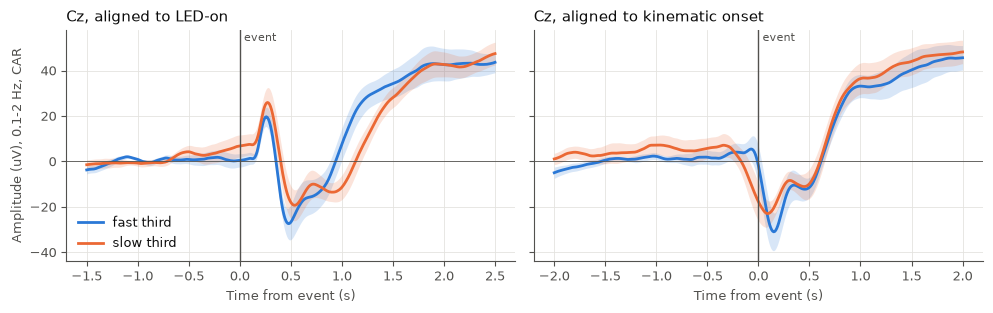

latency_shift_s  rt_shift_s
channel alignment                             
C3      led                  0.510       0.198
        onset               -0.005       0.198
Cz      led                  0.110       0.198
        onset               -0.055       0.198
Fp1     led                  0.150       0.198
        onset               -0.015       0.198

In [16]:
split = rt_split_table(results, cfg)
split.to_csv(run_dir / "rt_split.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
c = names.index("Cz")
for ax, event, title in zip(axes, ("led", "onset"), ("Cz, aligned to LED-on", "Cz, aligned to kinematic onset")):
    t = results[0]["erp_times"][event]
    for speed, color in (("fast", BLUE), ("slow", ORANGE)):
        x = np.stack([r["split"][event][speed][c] for r in results])
        draw(ax, t, x.mean(0), x.std(0, ddof=1) / np.sqrt(len(x)) if len(x) > 1 else 0 * t, color, f"{speed} third")
    mark(ax, "event")
    ax.axhline(0, color=MUTED, linewidth=0.6)
    ax.set_title(title, loc="left")
    ax.set_xlabel("Time from event (s)")
axes[0].set_ylabel("Amplitude (uV), 0.1-2 Hz, CAR")
axes[0].legend(loc="lower left")
fig.tight_layout()
save(fig, "rt_split")
summary = split.groupby(["channel", "alignment"])[["latency_shift_s", "rt_shift_s"]].median().round(3)
summary

In [17]:
peak = {e: np.array([r["split"][e]["fast"][cz] + r["split"][e]["slow"][cz] for r in results]) / 2 for e in ("onset", "led")}
amp = {e: np.array([np.nanmin(p[(results[0]["erp_times"][e] >= w[0]) & (results[0]["erp_times"][e] <= w[1])]) for p in peak[e]])
       for e, w in cfg["rt_split"]["peak_window_s"].items()}
alignment = paired_summary(amp["onset"], amp["led"])
metrics = {"subjects": cfg["subjects"], "n_lifts": int(overview.n_lifts.sum()), "n_kept": int(overview.n_kept.sum()),
           "filter_delay_ms": {str(k): v for k, v in delays.items()},
           "cz_peak_onset_minus_led_uv": alignment, "rt_split_median": summary.reset_index().to_dict("records"),
           "laterality": stats.to_dict("records"), "existence": existence.to_dict("records"), "asymmetry": asym_metrics}
(run_dir / "metrics.json").write_text(json.dumps(metrics, indent=2) + "\n", encoding="utf-8")
alignment

{'left_mean': -31.494354248046875,
 'right_mean': -27.563913345336914,
 'diff_mean': -3.9304416179656982,
 'diff_sd': 8.116583824157715,
 'n_negative': 6,
 'n_subjects': 10,
 'wilcoxon_p': 0.193359375}

## Summary

Run `output/diagnostics/pre-design/neurophysiology/20261106-132757`.

- **Eye activity dominates the MRCP band.** Fp1 and Fp2 reach about -275 and -210 uV after onset, against about -30 uV at Cz and C3, and start falling before LED-on.
- **No self-paced MRCP.** Before onset, Cz is +2.4 uV. A sharp negativity at Cz and C3 peaks about 0.15 s after onset, near onset once the causal delay is taken into account.
- **The C3-C4 slow asymmetry is not motor evidence.** It covers the whole scalp, is largest at F7-F8, and follows F7-F8 across subjects and lifts. This fits a horizontal eye-movement field. There is no EOG channel, so it is not proven.
- **ERD exists and is bilateral** in mu and beta.
- **Only beta supports right-hand movement:** left minus right cluster -6.5 points before onset (10/10, p 0.002). Mu is not lateralized. Handedness itself comes from the paper.
- **Onset and LED alignment** cannot be separated by amplitude. Fast and slow lifts show a cue-locked Cz peak at +0.26 s, then a later negativity closer to the movement.